# Experimento 02 - Análise Temática de Diálogos

#### Análise temática de textos em ambientes muito controlados

In [1]:
#pip install -r requirements.txt2

In [238]:
from pydantic import BaseModel, Field
from typing import List
from langchain_openai import AzureChatOpenAI
from langchain_openai.embeddings import AzureOpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from tqdm import tqdm
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader

### 1 - Jogo de palavras entre os duas pessoas

##### Aqui a ideia é gerar um prompt que pede um um "jogo de palavras". Cada pessoa tem um tema, e ela diz uma palavra relacionada. Dessa forma, é criado um ambiente com temas muito controlados.

##### 1.1 - Criando o prompt 

In [241]:
load_dotenv()

llm = AzureChatOpenAI(
    model="gpt-4o", 
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

system_prompt = """
Você é um assistente inteligente que vai construir um jogo de palavras entre duas personas, onde a persona 1 tem um tema e a persona 2 tem outro tema. 
Seu trabalho e gerar 500 rodadas desse jogo.

Siga o seguinte padrão para a conversa:

Persona 1: [palavra relacionada a {topico_1}]
Persona 2: [palavra relacionada a {topico_2}]
Persona 1: [outra palavra relacionada a {topico_1}]
Persona 2: [outra palavra relacionada a {topico_2}]
Persona 1: [outra palavra relacionada a {topico_1}]
Persona 2: [outra palavra relacionada a {topico_2}]
... 

Regra: gere apenas a Persona 1 e a Persona 2, e as palavras, sem explicações, sem número da rodada ou comentários adicionais.

"""


prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            ("human", "Gere a conversa entre as duas personas."),
        ]
)

chain = prompt | llm | StrOutputParser()

In [242]:
response = chain.invoke({
    "topico_1": "animais",
    "topico_2": "esportes"
})

In [243]:
response

'Persona 1: Tigre  \nPersona 2: Futebol  \n\nPersona 1: Leão  \nPersona 2: Basquete  \n\nPersona 1: Cavalo  \nPersona 2: Tênis  \n\nPersona 1: Canguru  \nPersona 2: Vôlei  \n\nPersona 1: Elefante  \nPersona 2: Natação  \n\nPersona 1: Águia  \nPersona 2: Boxe  \n\nPersona 1: Panda  \nPersona 2: Rugby  \n\nPersona 1: Girafa  \nPersona 2: Golfe  \n\nPersona 1: Lobo  \nPersona 2: Críquete  \n\nPersona 1: Jacaré  \nPersona 2: Hóquei  \n\nPersona 1: Arraia  \nPersona 2: Badminton  \n\nPersona 1: Camaleão  \nPersona 2: Escalada  \n\nPersona 1: Cavalo-marinho  \nPersona 2: Patinação  \n\nPersona 1: Coruja  \nPersona 2: Atletismo  \n\nPersona 1: Falcão  \nPersona 2: Esgrima  \n\nPersona 1: Cervo  \nPersona 2: Canoagem  \n\nPersona 1: Porco-espinho  \nPersona 2: Jiu-Jitsu  \n\nPersona 1: Anta  \nPersona 2: Surf  \n\nPersona 1: Tartaruga  \nPersona 2: Triatlo  \n\nPersona 1: Golfinho  \nPersona 2: Crossfit  \n\nPersona 1: Esquilo  \nPersona 2: Snowboarding  \n\nPersona 1: Bicho-preguiça  \nPerson

In [244]:
def pessoa (message: str) -> str:
    if message.startswith("Persona 1:"):
        return "Persona 1"
    elif message.startswith("Persona 2:"):
        return "Persona 2"
    else:
        return "Unknown"

conversa = response.split("\n")
conversa = [line for line in conversa if line.strip() != ""]
conversation_lista = [{"persona": pessoa (line), "mensagem": line[11:]} for line in conversa]

In [245]:
system_prompt_summary = """
Você é um assistente especializado na geração dos tópicos de cada rodada do jogo.

Sua tarefa é gerar apenas a palavra do tópico relacionado à rodada dada pela persona.

Sempre que a Persona 1 falar, você deve gerar a palavra {topico_1}.
Sempre que a Persona 2 falar, você deve gerar a palavra {topico_2}.

Você deve responder apenas com a palavra, sem nenhuma outra explicação ou pontuação.

Exemplo:
Input: Persona 1: Leão
Output: animais

Input: Persona 2: Futebol
Output: esportes
"""


prompt_summary = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt_summary),
            ("human", "Resuma a conversa dada: {conversation}"),
        ]
)

chain_summary = prompt_summary | llm | StrOutputParser()

In [246]:
summary_list = []
memory = []

for i in tqdm(range(len(conversa))):
    memory.append(conversa[i])
    memory_trimmed = memory[-10:]
    memory_str = "\n".join(memory_trimmed)
    response_summary = chain_summary.invoke({
        "topico_1": "animais",
        "topico_2": "esportes",
        "conversation": conversa[i]
    })
    
    summary_list.append(response_summary)

100%|██████████| 122/122 [00:53<00:00,  2.30it/s]


In [247]:
len(conversa), len(summary_list), len(conversation_lista)

(122, 122, 122)

In [248]:
all_data_list = []
for i in range(len(conversa)):
    all_data_list.append({
        "summary": summary_list[i],
        "persona": conversation_lista[i]["persona"],
        "mensagem": conversation_lista[i]["mensagem"]
    })

In [249]:
with open("data_json/conversation_data.json", "w", encoding="utf-8") as f:
    json.dump(all_data_list, f, ensure_ascii=False, indent=4)

In [250]:
with open("data_json/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   
    print(loaded_content[:5])

[{'summary': 'animais', 'persona': 'Persona 1', 'mensagem': 'Tigre  '}, {'summary': 'esportes', 'persona': 'Persona 2', 'mensagem': 'Futebol  '}, {'summary': 'animais', 'persona': 'Persona 1', 'mensagem': 'Leão  '}, {'summary': 'esportes', 'persona': 'Persona 2', 'mensagem': 'Basquete  '}, {'summary': 'animais', 'persona': 'Persona 1', 'mensagem': 'Cavalo  '}]


In [251]:
loaded_content[:5]

[{'summary': 'animais', 'persona': 'Persona 1', 'mensagem': 'Tigre  '},
 {'summary': 'esportes', 'persona': 'Persona 2', 'mensagem': 'Futebol  '},
 {'summary': 'animais', 'persona': 'Persona 1', 'mensagem': 'Leão  '},
 {'summary': 'esportes', 'persona': 'Persona 2', 'mensagem': 'Basquete  '},
 {'summary': 'animais', 'persona': 'Persona 1', 'mensagem': 'Cavalo  '}]

##### 1.2 - Embeddings

In [252]:
file_path_animais = "pdfs/revista_animais_continua.pdf"
loader_animais = PyPDFLoader(file_path_animais)
pages_animais = loader_animais.load()

print(f"{len(pages_animais)} páginas")

14 páginas


In [253]:
file_path_esportes = "pdfs/revista_esportes_continua.pdf"
loader_esportes = PyPDFLoader(file_path_esportes)
pages_esportes = loader_esportes.load()

print(f"{len(pages_esportes)} páginas")

18 páginas


In [374]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50,
    length_function=len,
    is_separator_regex=False,
)

In [375]:
chunks_esportes = text_splitter.split_documents(pages_esportes)
print(f"{len(chunks_esportes)} chunks")

chunks_animais = text_splitter.split_documents(pages_animais)
print(f"{len(chunks_animais)} chunks")

125 chunks
96 chunks


In [362]:
with open("data_json/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   

In [325]:
chunks = []
for item in loaded_content:
    chunks.append(item["summary"])

print(len(chunks))

122


In [376]:
embeddings = AzureOpenAIEmbeddings(
    model ="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

vectors_conversations = np.array(embeddings.embed_documents([chunk for chunk in chunks]))
vector_animais = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_animais]))
vector_esportes = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_esportes]))
all_vectors = np.concatenate([vectors_conversations, vector_animais, vector_esportes], axis=0)
all_vectors.shape

(343, 1536)

In [426]:
tsne = TSNE(n_components=2, random_state=42, perplexity = 37)
vectors_tsne = tsne.fit_transform(all_vectors)


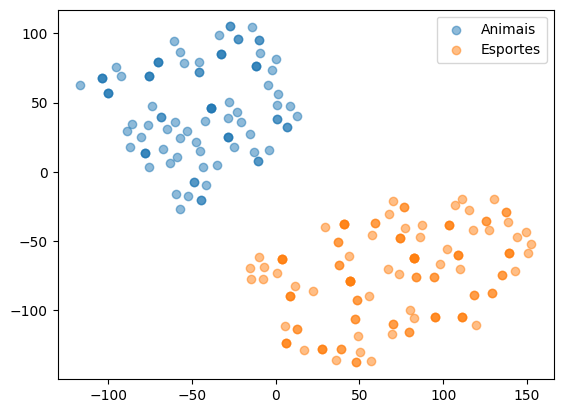

In [428]:
plt.scatter(vectors_tsne[len(vectors_conversations):len(vector_animais) + len(vectors_conversations), 0], vectors_tsne[len(vectors_conversations):len(vector_animais) + len(vectors_conversations), 1], label="Animais", alpha=0.5)
plt.scatter(vectors_tsne[len(vector_animais) + len(vectors_conversations):, 0], vectors_tsne[len(vector_animais) + len(vectors_conversations):, 1], label="Esportes", alpha=0.5)
plt.legend()
plt.show()